# Calculate metrics using climpred

---

Now that all of our model and observational data is ready for analysis, we can run this notebook and calculate ACC, RMSE and spread using climpred for each model, for one season at a time, and compare them as line plots against lead time. It is recommended that you use `dask` to run this notebook as we are working with geospatial data. Start the `dask` cluster first by running `cluster.ipynb`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os

import numpy as np
import pandas as pd
import xarray as xr
xr.set_options(keep_attrs=True)
import climpred
import intake
import matplotlib.pyplot as plt

import dask.config
dask.config.set({"array.slicing.split_large_chunks": False})

- Connect to the shared `dask` cluster (start it first by running `cluster.ipynb`).

In [2]:
from dask_cluster import get_client
client = get_client()

In [3]:
savefig = "no" #yes or no
plotdir = "plots/"
os.makedirs(plotdir, exist_ok=True)

## Here is where you choose your variable, metric and start/end time.

In [4]:
variable = ["t2m","tp"]
metrics = ["acc","rmse"]  # the line plot needs both: ACC (top row) and RMSE + spread (bottom row)
predict = "hindcast" #can be perfect or hindcast
data = "anom"
lead = "daily" #biweekly or daily
area = "geospatial"
start = "1999-01-01"
end = "2022-12-31"
season = "DJF" # JJA, DJF, ann
models = ["MPAS_60km","MPAS_120km","CAM6_ERA5","CESM2_ERA5"]
modeln = ["MPAS 60km","MPAS 120km","CAM6","CESM2"]
obs = "OBS_ERA5"  # Can be OBS_ERA5 or OBS_SUBX (CPC for tp and t2m)
domain = "global" #can be global or namerica

In [5]:
plot_settings = {"acc":  {"t2m": {"vmin": 0.0,"vmax": 1.0,"cmap": "OrRd"},
                          "tp": {"vmin": 0.0,"vmax": 0.7,"cmap": "OrRd"},
                          "default": {"vmin": 0.0,"vmax": 1.0,"cmap": "OrRd",
                                      "comp": "e2o","dim": "init","ens": "ensmean"},},
                 "rmse": {"psl": {"vmin": 0.0,"vmax": 500.0,"cmap": "viridis"},
                          "gh_500": {"vmin": 0.0,"vmax": 75.0,"cmap": "viridis"},
                          "default": {"vmin": 0.0,"vmax": 5.0,"cmap": "viridis",
                                     "comp": "e2o","dim": "init","ens": "ensmean"},},
                 "me":   {"default": {"vmin": -5.,"vmax": 5., "cmap": "RdBu_r",
                                      "comp": "e2o","dim": "init","ens": "ensmean"},}}

configs = {"t2m": {"acc_lim": (0.0, 1.0), "err_lim": (0.0, 5.0), "unit": " degK", "name": "2m Temperature"},
           "tp":  {"acc_lim": (0.0, 1.0), "err_lim": (0.0, 5.0), "unit": " mm/day", "name": "Precipitation"}}

## Now we read in and load the data into `dask`

We are using the intake catalog to find the data and load it up. The catalog is at located in this directory.

In [6]:
cat = intake.open_catalog("s2s_data_catalog.yml")

In [7]:
hinds = {}
for m in models:
    hinds[m] = cat[m](data=data, lead=lead, dim=area).to_dask().astype("float32")
    if domain == "namerica":
        hinds[m] = hinds[m].sel(lat=slice(15.0, 75.0),lon=slice(190.0, 305.0))
verif = cat[obs](data=data, lead=lead, dim=area).to_dask().astype("float32")
if domain == "namerica":
    verif = verif.sel(lat=slice(15.0, 75.0),lon=slice(190.0, 305.0))

- All of the model data is now loaded into a dictionary so that we can have them all together for comparison purposes.

In [8]:
# is seasonal data available for all models and rechunk
for h in hinds:
    print(hinds[h].init.dt.season.to_index().unique(), 'freq =',hinds[h].init.to_index().freq) # freq would show weekly but calendar conversion breaks this
    hinds[h] = hinds[h].chunk({"member": -1, "init": -1, "lead": -1, "lat": 45, "lon": 60}).persist()
    hinds[h] = hinds[h].sel(init=slice(start,end))
verif = verif.sel(time=slice(start,str(pd.to_datetime(end)+pd.DateOffset(days=47))))
verif = verif.chunk({"time": -1, "lat": 45, "lon": 60})

Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D


In [9]:
lmask = xr.open_dataset("lmask_360x181.nc")["lmask"]

## Create a Hindcast Ensemble in climpred for each of the models and run metrics

We are also setting kwargs (options) for `verify` in climpred. The second cell does the metric calculation using `verify` and computes it. Finally all models are concatenated together and plotted.

This could take a few minutes to run. If you are curious, check out the `dask` dashboard and you can watch the progress of the computations. The link should be like this: `https://jupyterhub.hpc.ucar.edu/stable/user/<username>/proxy/<port>/status`. Run `client.dashboard_link` to get it.

In [10]:
he = {}
met = {m: {} for m in metrics}
spr = {}
for h in hinds:
    print(h)
    # Work on a copy so hinds keeps the data as loaded: re-running this cell
    # (e.g. with a different season) then works without reloading.
    hind = hinds[h].copy()
    if season=="JJA":
        hind = hind.where(hind.init.dt.month.isin([6,7,8]),drop=True)
    elif season=="DJF":
        hind = hind.where(hind.init.dt.month.isin([1,2,12]),drop=True)

    hind["t2m"] = hind.t2m.where(lmask==False); hind["tp"] = hind.tp.where(lmask==False)
    hind["lead"].attrs["units"] = 'days'

    if predict == "perfect":
        he[h] = climpred.PerfectModelEnsemble(hind)
    elif predict == "hindcast":
        he[h] = climpred.HindcastEnsemble(hind).add_observations(verif)

    # Compute each metric in the metrics list from the same ensemble
    for metric in metrics:
        ms = plot_settings.get(metric,{}).get("default",{})
        comparison = "e2c" if predict == "perfect" else ms.get("comp")
        met[metric][h] = he[h].verify(metric=metric,comparison=comparison,dim=ms.get("dim"),
                                      alignment="same_inits",reference=None,skipna=True).compute()
    spr[h] = hind.std("member").mean("init").compute()

met_all = {metric: xr.concat([met[metric][m] for m in models], dim="model").assign_coords(model=models)
           for metric in metrics}
spr_all = xr.concat([spr[m] for m in models], dim="model").assign_coords(model=models)

MPAS_60km
MPAS_120km
CAM6_ERA5
CESM2_ERA5


In [11]:
# Area-weighted averages (excluding south of 60S) for the line plot
acc_all = met_all["acc"].where(met_all["acc"].lat>-60.0)
acc_weight = acc_all.weighted(np.cos(np.deg2rad(acc_all.lat))).mean(("lat","lon")).compute()
rmse_all = met_all["rmse"].where(met_all["rmse"].lat>-60.0)
rmse_weight = rmse_all.weighted(np.cos(np.deg2rad(rmse_all.lat))).mean(("lat","lon")).compute()
spr_weight = spr_all.where(spr_all.lat>-60.0).weighted(np.cos(np.deg2rad(spr_all.lat))).mean(("lat","lon")).compute()

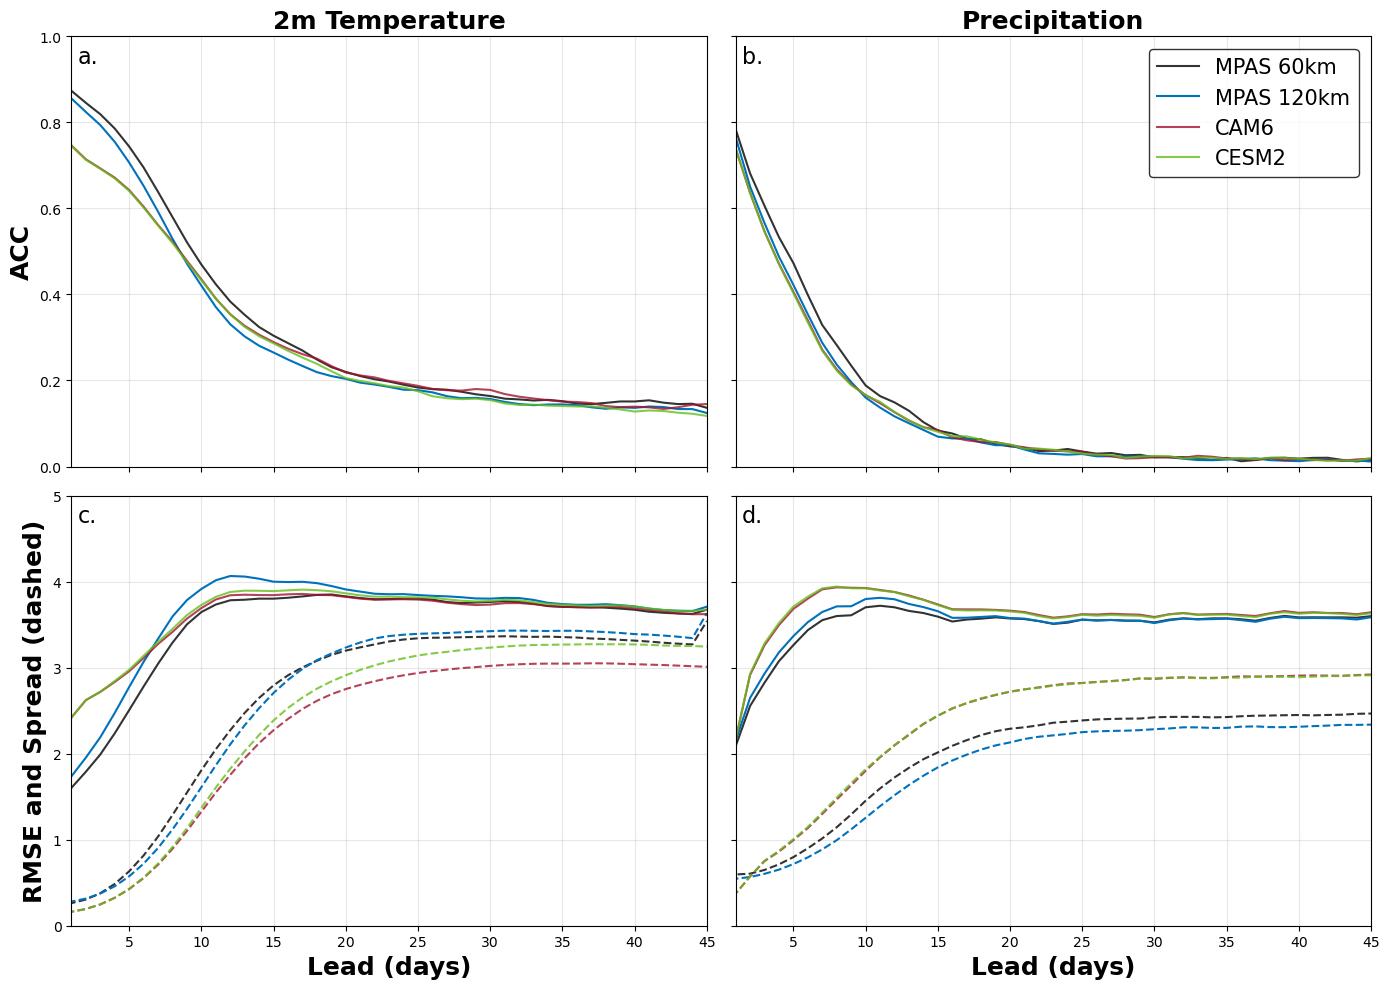

In [12]:
n_models = len(models)
colors = ["black",(0,0.4470,0.7410),(0.6350,0.0780,0.1840),(0.4,0.75,0.1)][-n_models:]
alphas = [0.8,1.0,0.8,0.8][-n_models:]

fig, axes = plt.subplots(2,2,figsize=(14,10),sharex=True,sharey="row")

for col_idx, vv in enumerate(variable):
    conf = configs.get(vv, {})
    var_name = conf.get("name", vv.upper())
    ax_top = axes[0,col_idx]; ax_bot = axes[1,col_idx]

    for i in range(n_models):
        rmse_weight[vv].sel(model=models[i]).plot(ax=ax_bot,color=colors[i],alpha=alphas[i],label=modeln[i])
        spr_weight[vv].sel(model=models[i]).plot(ax=ax_bot,color=colors[i],alpha=alphas[i],linestyle="dashed")
        acc_weight[vv].sel(model=models[i]).plot(ax=ax_top,color=colors[i],alpha=alphas[i],label=modeln[i])

    ax_top.set_xlim(1,45); ax_bot.set_xlim(1,45)
    ax_top.minorticks_off(); ax_bot.minorticks_off()

    if conf.get("err_lim"):
        ax_bot.set_ylim(conf.get("err_lim"))
    if conf.get("acc_lim"):
        ax_top.set_ylim(conf.get("acc_lim"))

    ax_top.set_title(f"{var_name}",fontsize=18,fontweight="bold")
    ax_bot.set_title(""); ax_top.set_xlabel("")
    ax_bot.set_xlabel("Lead (days)",fontsize=18,fontweight="bold")

    if col_idx==0:
        ax_bot.set_ylabel(f"RMSE and Spread (dashed)".strip(),fontsize=18,fontweight="bold")
        ax_top.set_ylabel("ACC",fontsize=18,fontweight="bold")
    else:
        ax_top.set_ylabel(""); ax_bot.set_ylabel("")

panel_labels = ["a.","b.","c.","d."]
for ax, label in zip(axes.flat,panel_labels):
    ax.grid(True,alpha=0.3)
    ax.text(0.01,0.98,label,transform=ax.transAxes,fontsize=16,va="top",bbox=dict(facecolor="white",alpha=0.5,edgecolor="none",boxstyle="round,pad=0.01"))

for ax in axes.flat:
    ax.grid(True,alpha=0.3)
axes[0,1].legend(borderaxespad=0.6,edgecolor="black",prop={"size": 15})

plt.tight_layout()
if savefig=="yes":
    plt.savefig(f"{plotdir}figure1_{domain}_{season}.jpg",dpi=300,bbox_inches="tight")